In [1]:
# --- arranque en Colab (no hace nada fuera de Colab) -----------------------
# Colab arranca en /content con un entorno vacío: sin esta celda el
# `import environment` siguiente falla con ModuleNotFoundError. Generada por
# tools/py_to_notebook.py -- editala ahí, no acá.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/solidgoldmagickarp/proyecto_de_lenguaje_emergente.git"
    REPO_DIR = "proyecto_de_lenguaje_emergente"

    # El orden de las guardas importa: primero probar DÓNDE estamos, después qué hay en disco.
    # `isdir(REPO_DIR)` es relativo, así que chequearlo primero clonaría una copia
    # anidada en cualquier re-ejecución de esta celda dentro de la misma sesión (algo rutinario).
    if os.path.basename(os.getcwd()) != REPO_DIR:
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
        os.chdir(REPO_DIR)
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True
    )

    # El disco de Colab es EFÍMERO: cada checkpoint se pierde cuando el entorno de ejecución
    # se desconecta (~90 min de inactividad en el plan gratuito), y las Etapas 3, 4 y 5 necesitan
    # todas los checkpoints de la Etapa 2. Descomentá para guardarlos en Drive en su lugar.
    #
    # Notar `islink`, no `exists`: importar `environment` crea un directorio checkpoints/
    # REAL, y `exists` entonces saltearía el enlace en silencio y mandaría cada
    # checkpoint de vuelta al disco efímero.
    #
    # from google.colab import drive
    # drive.mount("/content/drive")
    # PERSISTENT = "/content/drive/MyDrive/proyecto_de_lenguaje_emergente/checkpoints"
    # os.makedirs(PERSISTENT, exist_ok=True)
    # if os.path.islink("checkpoints"):
    #     print("checkpoints ->", os.readlink("checkpoints"))
    # elif os.path.isdir("checkpoints"):
    #     print("ADVERTENCIA: checkpoints/ ya es un directorio real, así que NO está en Drive.")
    #     print("Mové su contenido a", PERSISTENT, ", borralo, y volvé a ejecutar esta celda.")
    # else:
    #     os.symlink(PERSISTENT, "checkpoints")
    #     print("checkpoints ->", PERSISTENT)

    print("Arranque en Colab OK. Directorio de trabajo:", os.getcwd())

# Etapa 1 · Tokenización — un BPE propio

Entrenamos un BPE a nivel byte sobre TinyStories con `tokenizers` (la librería de bajo nivel de HF) y lo
comparamos con el tokenizador de GPT-2. El artefacto que sale de acá, `checkpoints/tokenizer.json`, lo leen
todas las etapas siguientes.

In [2]:
import environment  # noqa: F401  (importar antes que tokenizers/datasets)

environment.summary()

SMOKE_TEST = False  # True: corpus mínimo, corre en segundos. False: la corrida que va al informe.
SEED = 1337

VOCAB_SIZE = 8192
TOKENIZER_TRAIN_STORIES = 5_000 if SMOKE_TEST else 200_000
EVAL_STORIES = 500 if SMOKE_TEST else 5_000        # cuentos de validación, nunca vistos por el tokenizador
SWEEP_TRAIN_STORIES = 2_000 if SMOKE_TEST else 50_000
VOCAB_SWEEP = [1024, 2048, 4096, 8192, 16384]
N_EMBD_REFERENCE = 256                             # para traducir V a parámetros de embedding + lm_head

ENTORNO
os             : Windows 11
python         : 3.13.15
venv           : C:\dev\ia-generativa-sistemas-multiagente\tp\1\proyecto_de_lenguaje_emergente\.venv
cpu            : Intel64 Family 6 Model 158 Stepping 10, GenuineIntel
logical_cores  : 6
torch          : 2.11.0+cu128
torch_threads  : 6
cuda_available : True
gpu            : NVIDIA GeForce RTX 3050
gpu_memory_gb  : 6.44
ram_total_gb   : 17.1
ram_free_gb    : 5.1
--------------------------------------------------------------
HF_HOME        : C:\Users\juani\.cache\huggingface
ca_bundle      : no presente (normal)


## Datos

El tokenizador se entrena sobre el split `train`; todas las mediciones se hacen sobre `validation`, así el
conteo de tokens por cuento no está inflado a favor del BPE propio por haber visto esos mismos cuentos.

In [3]:
from data import load_tinystories

train_stories = load_tinystories("train", limit=TOKENIZER_TRAIN_STORIES)["text"]
eval_stories = load_tinystories("validation", limit=EVAL_STORIES)["text"]
print(f"cuentos para entrenar el tokenizador: {len(train_stories):,}")
print(f"cuentos de validación para medir     : {len(eval_stories):,}")

cuentos para entrenar el tokenizador: 200,000
cuentos de validación para medir     : 5,000


## Entrenar el BPE a nivel byte

In [4]:
import time

from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers

EOS = "<|endoftext|>"


def train_bpe(texts, vocab_size):
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=[EOS],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        show_progress=False,
    )
    tok.train_from_iterator(texts, trainer=trainer, length=len(texts))
    return tok


t0 = time.time()
tokenizer = train_bpe(train_stories, VOCAB_SIZE)
print(f"entrenado en {time.time() - t0:.1f}s -- vocabulario: {tokenizer.get_vocab_size():,}")
tokenizer.save("checkpoints/tokenizer.json")
print("guardado: checkpoints/tokenizer.json")

entrenado en 67.9s -- vocabulario: 8,192
guardado: checkpoints/tokenizer.json


## Ida y vuelta

`decode(encode(x)) == x` tiene que dar exacto en *todos* los cuentos de validación, no en uno elegido a mano.
A nivel byte no puede haber tokens desconocidos, así que cualquier diferencia sería un bug de configuración
(por ejemplo, olvidarse del `decoder`).

In [5]:
story = eval_stories[0]
enc = tokenizer.encode(story)
print(story[:300], "...\n")
print("primeros 20 tokens:", enc.tokens[:20])
print("primeros 20 ids   :", enc.ids[:20])

failures = [s for s in eval_stories if tokenizer.decode(tokenizer.encode(s).ids) != s]
print(f"\nida y vuelta exacta: {len(eval_stories) - len(failures)}/{len(eval_stories)}")
if failures:
    print("primer fallo:", repr(failures[0][:200]))

Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."

After playing with the car, Kitty and Spot felt thirsty. They found a small pond with clear water. They drank the water and felt very happy. They ...

primeros 20 tokens: ['Spot', '.', 'ĠSpot', 'Ġsaw', 'Ġthe', 'Ġshiny', 'Ġcar', 'Ġand', 'Ġsaid', ',', 'Ġ"', 'Wow', ',', 'ĠKitty', ',', 'Ġyour', 'Ġcar', 'Ġis', 'Ġso', 'Ġbright']
primeros 20 ids   : [2967, 14, 1125, 410, 263, 959, 564, 265, 328, 12, 332, 1292, 12, 2969, 12, 626, 564, 403, 354, 1113]



ida y vuelta exacta: 5000/5000


## Los primeros merges

El orden de los merges es el orden de frecuencia de los pares en el corpus de entrenamiento. `Ġ` (U+0120) es
cómo el BPE a nivel byte representa el espacio adelante de una palabra.

In [6]:
import json


def merges_of(tok):
    merges = json.loads(tok.to_str())["model"]["merges"]
    # según la versión de `tokenizers`, cada merge es "a b" o ["a", "b"]
    return [tuple(m.split(" ", 1)) if isinstance(m, str) else tuple(m) for m in merges]


merges = merges_of(tokenizer)
print(f"merges aprendidos: {len(merges):,}\n")
for i, (a, b) in enumerate(merges[:30], start=1):
    print(f"{i:>3}. {a!r:>10} + {b!r:<10} -> {a + b!r}")

merges aprendidos: 7,935

  1.        'h' + 'e'        -> 'he'
  2.        'Ġ' + 't'        -> 'Ġt'
  3.        'Ġ' + 'a'        -> 'Ġa'
  4.        'Ġ' + 's'        -> 'Ġs'
  5.        'Ġ' + 'w'        -> 'Ġw'
  6.        'n' + 'd'        -> 'nd'
  7.       'Ġt' + 'he'       -> 'Ġthe'
  8.        'e' + 'd'        -> 'ed'
  9.       'Ġa' + 'nd'       -> 'Ġand'
 10.       'Ġt' + 'o'        -> 'Ġto'
 11.        'Ġ' + 'b'        -> 'Ġb'
 12.        'i' + 'n'        -> 'in'
 13.        'Ġ' + 'h'        -> 'Ġh'
 14.       'Ġw' + 'a'        -> 'Ġwa'
 15.        'r' + 'e'        -> 're'
 16.        'o' + 'u'        -> 'ou'
 17.        'Ġ' + 'f'        -> 'Ġf'
 18.        'i' + 't'        -> 'it'
 19.        'Ġ' + 'l'        -> 'Ġl'
 20.        'Ġ' + 'c'        -> 'Ġc'
 21.        'Ġ' + 'd'        -> 'Ġd'
 22.        'e' + 'r'        -> 'er'
 23.        'Ġ' + 'he'       -> 'Ġhe'
 24.        'Ġ' + 'm'        -> 'Ġm'
 25.        'Ġ' + 'p'        -> 'Ġp'
 26.      'Ġwa' + 's'        -> 'Ġwas'
 27

In [7]:
# Los últimos merges muestran lo contrario: qué entra al vocabulario cuando ya no queda nada frecuente.
for i, (a, b) in enumerate(merges[-15:], start=len(merges) - 14):
    print(f"{i:>5}. {a!r:>12} + {b!r:<12} -> {a + b!r}")

 7921.     'Ġcrawl' + 's'          -> 'Ġcrawls'
 7922.      'Ġsnap' + 's'          -> 'Ġsnaps'
 7923.        'ĠEx' + 'cited'      -> 'ĠExcited'
 7924.      'Ġconv' + 'ince'       -> 'Ġconvince'
 7925.          'O' + 'ut'         -> 'Out'
 7926.          'l' + 'ied'        -> 'lied'
 7927.         'll' + 'as'         -> 'llas'
 7928.       'ĠYou' + 'Ã¢'         -> 'ĠYouÃ¢'
 7929.        'ell' + 'e'          -> 'elle'
 7930.        'Ġbl' + 'own'        -> 'Ġblown'
 7931.         'Åĵ' + 'See'        -> 'ÅĵSee'
 7932.       'Ġste' + 'w'          -> 'Ġstew'
 7933.     'Ġvisit' + 'ors'        -> 'Ġvisitors'
 7934.       'Ġrob' + 'in'         -> 'Ġrobin'
 7935.         'ĠZ' + 'ee'         -> 'ĠZee'


## BPE propio contra GPT-2 sobre los mismos cuentos

`tiktoken` baja el encoding la primera vez (necesita red). `gpt2` = `r50k_base`, 50.257 tokens; `cl100k_base`
(GPT-3.5/4, ~100K) va como tercer dato.

In [8]:
import numpy as np
import tiktoken

encoders = {f"BPE propio (V={tokenizer.get_vocab_size():,})": lambda s: len(tokenizer.encode(s).ids)}
for name in ("gpt2", "cl100k_base"):
    try:
        e = tiktoken.get_encoding(name)
        encoders[f"tiktoken {name} (V={e.n_vocab:,})"] = lambda s, e=e: len(e.encode(s, allowed_special="all"))
    except Exception as exc:  # sin red, por ejemplo
        print(f"no se pudo cargar {name}: {exc}")

n_chars = np.array([len(s) for s in eval_stories])
n_words = np.array([len(s.split()) for s in eval_stories])
token_counts = {}
print(f"{'tokenizador':<34} {'tok/cuento':>10} {'mediana':>8} {'p90':>6} {'chars/tok':>9} {'tok/palabra':>11}")
for name, fn in encoders.items():
    counts = np.array([fn(s) for s in eval_stories])
    token_counts[name] = counts
    print(
        f"{name:<34} {counts.mean():>10.1f} {np.median(counts):>8.0f} {np.percentile(counts, 90):>6.0f} "
        f"{n_chars.sum() / counts.sum():>9.2f} {counts.sum() / n_words.sum():>11.3f}"
    )

own_name, gpt2_name = list(token_counts)[:2] if len(token_counts) > 1 else (list(token_counts)[0], None)
if gpt2_name:
    ratio = token_counts[gpt2_name] / token_counts[own_name]
    print(f"\nGPT-2 usa en promedio {ratio.mean():.3f}x los tokens del BPE propio (por cuento)")

tokenizador                        tok/cuento  mediana    p90 chars/tok tok/palabra


BPE propio (V=8,192)                    195.7      181    254      4.15       1.235


tiktoken gpt2 (V=50,257)                199.0      184    258      4.08       1.256


tiktoken cl100k_base (V=100,277)        190.9      177    248      4.26       1.205

GPT-2 usa en promedio 1.018x los tokens del BPE propio (por cuento)


In [9]:
# ¿Dónde está la diferencia? Mismo cuento, token por token.
if gpt2_name:
    gpt2_enc = tiktoken.get_encoding("gpt2")
    sample = eval_stories[1][:250]
    print("BPE propio:", [tokenizer.id_to_token(i) for i in tokenizer.encode(sample).ids])
    print()
    print("GPT-2     :", [gpt2_enc.decode_single_token_bytes(i).decode("utf-8", "replace") for i in gpt2_enc.encode(sample)])

BPE propio: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġin', 'Ġa', 'Ġbig', 'Ġforest', ',', 'Ġthere', 'Ġlived', 'Ġa', 'Ġrhinoceros', 'Ġnamed', 'ĠRo', 'xy', '.', 'ĠRo', 'xy', 'Ġloved', 'Ġto', 'Ġclimb', '.', 'ĠShe', 'Ġclimbed', 'Ġtrees', ',', 'Ġrocks', ',', 'Ġand', 'Ġhills', '.', 'ĠOne', 'Ġday', ',', 'ĠRo', 'xy', 'Ġfound', 'Ġan', 'Ġicy', 'Ġhill', '.', 'ĠShe', 'Ġhad', 'Ġnever', 'Ġseen', 'Ġanything', 'Ġlike', 'Ġit', 'Ġbefore', '.', 'ĠIt', 'Ġwas', 'Ġshiny', 'Ġand', 'Ġcold', ',', 'Ġand', 'Ġshe', 'Ġwanted', 'Ġto', 'Ġcl']

GPT-2     : ['Once', ' upon', ' a', ' time', ',', ' in', ' a', ' big', ' forest', ',', ' there', ' lived', ' a', ' rh', 'in', 'oc', 'eros', ' named', ' R', 'oxy', '.', ' R', 'oxy', ' loved', ' to', ' climb', '.', ' She', ' climbed', ' trees', ',', ' rocks', ',', ' and', ' hills', '.', ' One', ' day', ',', ' R', 'oxy', ' found', ' an', ' icy', ' hill', '.', ' She', ' had', ' never', ' seen', ' anything', ' like', ' it', ' before', '.', ' It', ' was', ' shiny', ' and', ' cold', ','

## Uso del vocabulario

¿Cuántas de las filas del vocabulario aparecen realmente en texto nuevo? Las que no aparecen casi nunca durante
el preentrenamiento van a quedar cerca de su inicialización al azar (esto vuelve en la Etapa 3).

In [10]:
from collections import Counter

usage = Counter(i for s in eval_stories for i in tokenizer.encode(s).ids)
vocab = tokenizer.get_vocab()
whole_word = [t for t in vocab if t.startswith("Ġ") and t[1:].isalpha()]
print(f"tokens distintos usados en validación : {len(usage):,} / {tokenizer.get_vocab_size():,}")
print(f"tokens de palabra entera (Ġ + letras) : {len(whole_word):,}")
print(f"tokens que aparecen <= 2 veces        : {sum(1 for t in range(tokenizer.get_vocab_size()) if usage[t] <= 2):,}")
print("\nlos 15 más frecuentes:", [(tokenizer.id_to_token(i), c) for i, c in usage.most_common(15)])

tokens distintos usados en validación : 6,911 / 8,192
tokens de palabra entera (Ġ + letras) : 5,954
tokens que aparecen <= 2 veces        : 2,215

los 15 más frecuentes: [('.', 68289), ('Ġand', 36036), (',', 35940), ('Ġthe', 35722), ('Ċ', 31618), ('Ġto', 27905), ('Ġa', 25348), ('Ġwas', 23100), ('Ġit', 11664), ('Ġher', 10290), ('Ġhe', 8868), ('ĠHe', 8613), ('ĠShe', 8501), ('Ġshe', 7493), ('Ġin', 7032)]


## El toma y daca `V ↔ T`, medido

Mismo corpus, varios tamaños de vocabulario. Para cada uno: tokens por cuento (T, lo que cuesta el contexto y
el cómputo por cuento) contra parámetros de embedding + `lm_head` con `n_embd=256` (lo que cuesta V en el
modelo), y qué fracción del vocabulario se usa en validación.

      V tok/cuento entra en 192  V usado params emb+head
  1,024      263.8        15.1%    83.4%         525,312
  2,048      223.4        36.5%    90.7%       1,050,624
  4,096      204.1        52.8%    91.2%       2,101,248
  8,192      195.8        60.4%    84.2%       4,202,496
 16,384      194.2        61.5%    54.6%       8,404,992


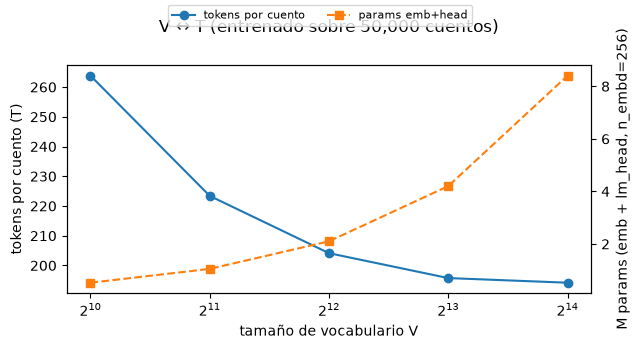

In [11]:
import matplotlib.pyplot as plt

sweep_rows = []
for v in VOCAB_SWEEP:
    tok_v = train_bpe(train_stories[:SWEEP_TRAIN_STORIES], v)
    counts = np.array([len(tok_v.encode(s).ids) for s in eval_stories])
    used = len({i for s in eval_stories for i in tok_v.encode(s).ids})
    real_v = tok_v.get_vocab_size()
    sweep_rows.append({
        "vocab": real_v,
        "tokens_per_story": float(counts.mean()),
        "frac_stories_fit_192": float((counts + 1 <= 192).mean()),
        "vocab_used_frac": used / real_v,
        "emb_plus_head_params": 2 * real_v * N_EMBD_REFERENCE + real_v,
    })

print(f"{'V':>7} {'tok/cuento':>10} {'entra en 192':>12} {'V usado':>8} {'params emb+head':>15}")
for r in sweep_rows:
    print(
        f"{r['vocab']:>7,} {r['tokens_per_story']:>10.1f} {r['frac_stories_fit_192']:>12.1%} "
        f"{r['vocab_used_frac']:>8.1%} {r['emb_plus_head_params']:>15,}"
    )

fig, ax1 = plt.subplots(figsize=(6.5, 3.5))
vs = [r["vocab"] for r in sweep_rows]
ax1.plot(vs, [r["tokens_per_story"] for r in sweep_rows], "o-", label="tokens por cuento")
ax1.set_xscale("log", base=2)
ax1.set_xlabel("tamaño de vocabulario V")
ax1.set_ylabel("tokens por cuento (T)")
ax2 = ax1.twinx()
ax2.plot(vs, [r["emb_plus_head_params"] / 1e6 for r in sweep_rows], "s--", color="tab:orange", label="params emb+head")
ax2.set_ylabel("M params (emb + lm_head, n_embd=256)")
fig.legend(loc="upper center", ncol=2, fontsize=8)
ax1.set_title(f"V ↔ T (entrenado sobre {SWEEP_TRAIN_STORIES:,} cuentos)", pad=24)
fig.tight_layout()
fig.savefig("checkpoints/stage1_vocab_tradeoff.png", dpi=110)
plt.show()

In [12]:
stats = {
    "smoke_test": SMOKE_TEST,
    "vocab_size": tokenizer.get_vocab_size(),
    "tokenizer_train_stories": len(train_stories),
    "eval_stories": len(eval_stories),
    "roundtrip_failures": len(failures),
    "first_merges": ["".join(m) for m in merges[:20]],
    "mean_tokens_per_story": {k: float(v.mean()) for k, v in token_counts.items()},
    "vocab_used_in_validation": len(usage),
    "vocab_sweep": sweep_rows,
}
with open("checkpoints/stage1_stats.json", "w", encoding="utf-8") as f:
    json.dump(stats, f, ensure_ascii=False, indent=2)
print("guardado: checkpoints/stage1_stats.json")

guardado: checkpoints/stage1_stats.json


## Para el informe

- ¿Qué merges aparecieron primero, y qué les dicen sobre cómo está armado este corpus? ¿Qué esperarían en un
  corpus de código?
- Con el vocabulario elegido, ¿cuántos tokens por cuento en promedio, y cómo se compara con GPT-2 sobre los
  mismos cuentos? ¿Por qué la diferencia tiene ese tamaño y no otro?
- ¿Un vocabulario más chico es siempre mejor acá, o hay algo que se paga a cambio? (miren la tabla del barrido:
  T, fracción de cuentos que entran en la ventana y parámetros de embedding).